# Measuring a trademark drawing’s similarity to its filing year

How typical are the colors in one drawing among the drawings filed that year? This small example calculates that score from six synthetic drawings. By changing the colors or assigning a drawing to a different year, you can see which choices move the score.

The inputs, background threshold, and scores in this notebook are illustrative. Running it requires Python, NumPy, and Pillow. All data are generated in memory.

## 1. Make two small filing cohorts

Each cohort contains three drawings. Year 1 contains two red marks and one blue mark. Year 2 reverses these frequencies. Drawing different shapes in the same color lets us check what a color-only measure picks up.

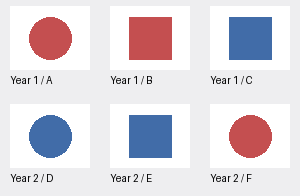

In [1]:
import numpy as np
from PIL import Image, ImageCms, ImageDraw

red, blue = "#c44f50", "#416ca8"
records = [
    (1, "A", "circle", red),  (1, "B", "square", red),  (1, "C", "square", blue),
    (2, "D", "circle", blue), (2, "E", "square", blue), (2, "F", "circle", red),
]

images = []
sheet = Image.new("RGB", (300, 196), "#eeeef0")
for index, (year, label, shape, color) in enumerate(records):
    drawing = Image.new("RGB", (80, 64), "white")
    pen = ImageDraw.Draw(drawing)
    bounds = (19, 11, 61, 53)
    if shape == "circle":
        pen.ellipse(bounds, fill=color)
    else:
        pen.rectangle(bounds, fill=color)
    images.append(drawing)
    x, y = 100 * (index % 3) + 10, 98 * (index // 3) + 6
    sheet.paste(drawing, (x, y))
    ImageDraw.Draw(sheet).text((x, y + 68), f"Year {year} / {label}", fill="black")

sheet

## 2. Measure each drawing’s color distribution

Pillow converts sRGB to CIELAB through its color management library. The lightness channel is rescaled to 0–100. Subtracting 128 from each chromatic channel locates neutral gray at zero. The example discards very light, nearly neutral background pixels, then counts the remaining pixels in 4 × 6 × 6 bins. L2 normalization gives each drawing a unit-length vector.

In [2]:
srgb_to_lab = ImageCms.buildTransformFromOpenProfiles(
    ImageCms.createProfile("sRGB"), ImageCms.createProfile("LAB"), "RGB", "LAB"
)

def color_vector(drawing):
    lab = ImageCms.applyTransform(drawing.convert("RGB"), srgb_to_lab)
    lightness, green_red, blue_yellow = [
        np.asarray(channel, dtype=float) for channel in lab.split()
    ]
    lightness *= 100 / 255
    green_red -= 128
    blue_yellow -= 128
    chroma = np.hypot(green_red, blue_yellow)
    foreground = (lightness < 95) | (chroma > 5)
    if not foreground.any():
        raise ValueError("The drawing has no foreground after background removal.")
    pixels = np.column_stack([channel[foreground] for channel in (lightness, green_red, blue_yellow)])
    histogram, _ = np.histogramdd(pixels, bins=(4, 6, 6), range=((0, 100), (-128, 128), (-128, 128)))
    counts = histogram.ravel()
    return counts / np.linalg.norm(counts)

vectors = np.stack([color_vector(drawing) for drawing in images])
assert vectors.shape == (6, 144)
assert np.allclose(np.linalg.norm(vectors, axis=1), 1)
print(f"{len(vectors)} drawings × {vectors.shape[1]} color bins")

6 drawings × 144 color bins


## 3. Compare each drawing with its own filing year

Average the unit vectors within a year, including the focal drawing. The dot product with the normalized annual mean is cosine similarity. The reference vector changes with the cohort’s palette, so the same red drawing can have a different score in the two years.

In [3]:
years = np.array([record[0] for record in records])
scores = np.zeros(len(records))
for year in np.unique(years):
    in_year = years == year
    annual_mean = vectors[in_year].mean(axis=0)
    annual_direction = annual_mean / np.linalg.norm(annual_mean)
    scores[in_year] = vectors[in_year] @ annual_direction

print("Year  Drawing  Color   Similarity")
for (year, label, shape, color), score in zip(records, scores):
    color_name = "red" if color == red else "blue"
    print(f"{year:>4}  {label:^7}  {color_name:<5}  {score:>10.3f}")

Year  Drawing  Color   Similarity
   1     A     red         0.894
   1     B     red         0.894
   1     C     blue        0.447
   2     D     blue        0.894
   2     E     blue        0.894
   2     F     red         0.447


A and B receive the same score even though one is a circle and the other is a square. Both use the common color in Year 1. F uses the same pigment in Year 2, when red is rare, and receives a lower score. In a sample this small, including the focal drawing has a noticeable influence on the annual mean. This exercise illustrates color measurement only. The trademark study measures visual form separately with CLIP.